# EEG Processing - starting with epochs

This notebook is to perform EEG processing starting at the epochs.

## 📦 Imports

In [1]:
%matplotlib widget
import mindmap as mm
import mne

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Raw EEGs

🎚️ **<font color=pink>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id
- `samp`: EEG sample

In [2]:
# ------------ Parameters -------------
fconfig = "../../papers/intra/configuration.yml"
sub     = "50"
task    = "spk"
run     = None
# -------------------------------------

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "eeg", task=task, run=run)

DATA SUMMARY
Dataset: intra
Subject: 50
Task: spk
Run: None
Retrieved objects:
- eeg
Missing objects:


📊 **EEG signal**

Using matplotlib as 2D backend.


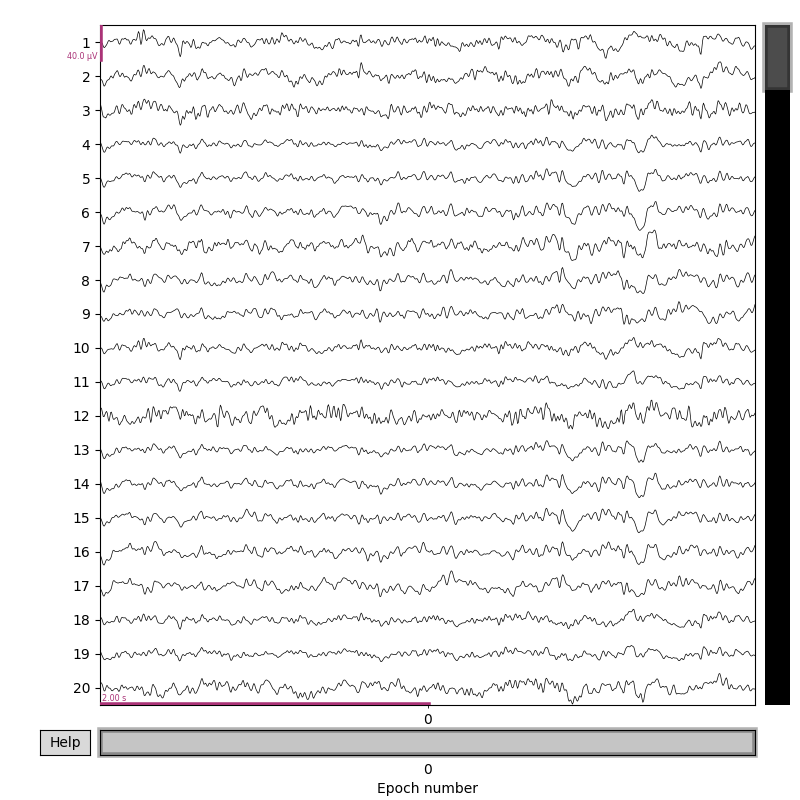

In [3]:
_ = data["eeg"][0].plot()

MNE type: <class 'mne.epochs.EpochsArray'>
Not setting metadata
130 matching events found
No baseline correction applied
0 projection items activated
combining channels using GFP (eeg channels)


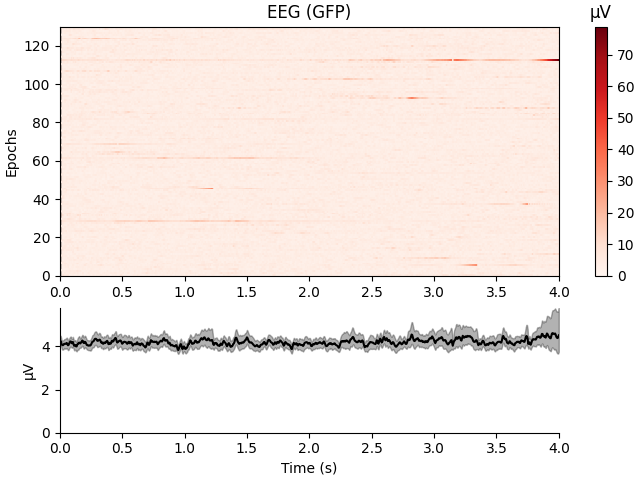

In [4]:
print(f"MNE type: {type(data['eeg'])}")
_ = data["eeg"].plot_image()

📊 **Temporal Fourier spectrum**

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


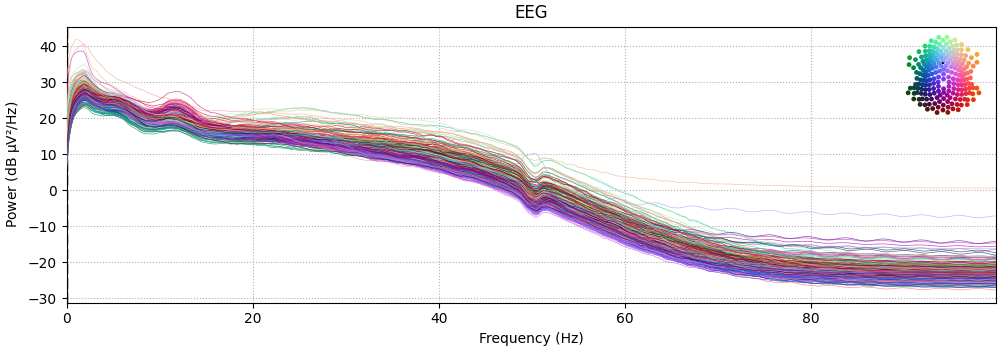

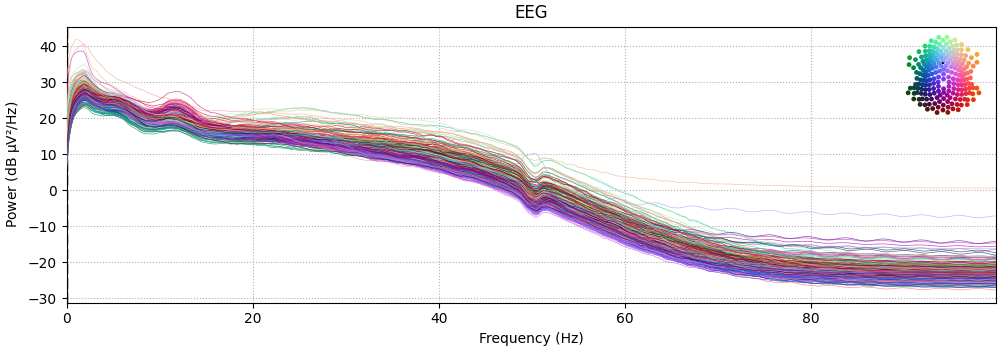

In [5]:
psd = data["eeg"].compute_psd().plot()

## ⚙️ Processing

1. Filtering (hopefully done before epoching)
2. Bad channel detection / interpolation (hopefully done before epoching)
3. Re-reference (average reference)
4. Baseline correction
5. Artifact rejection / ICA
6. Compute noise covariance
7. Average epochs

#### 1. Filtering

**Notch filter**: A prevalent source of noise in recordings from electrical devices is the 50 Hz electrical interference. To mitigate this type of noise, it is advisable to apply a notch filter, which is a band-stop filter specifically designed to attenuate frequencies around 50 Hz.

In [6]:
# data["eeg"] = data["eeg"].filter(
#     l_freq = 63,
#     h_freq = 37,
#     picks  = "all",
#     method = "fir",
# )

#### 2. Bad channel interpolation

After observing the time series and Fourier transform, we can identify any electrodes that did not record properly. In such cases, we interpolate the faulty channels to prevent them from 
affecting the rest of the analysis. <br>

🎚️ **<font color=pink>Bad channels</font>**:
- `bads`: List of bad channels by name.

In [7]:
# ------------ Parameters -------------
bads = []
# -------------------------------------

for b in bads:
    data["eeg"].info["bads"].append(b)
data["eeg"] = data["eeg"].interpolate_bads(method={"eeg":"spline"})

Setting channel interpolation method to {'eeg': 'spline'}.


/tmp/ipykernel_49917/3322194614.py:7: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  data["eeg"] = data["eeg"].interpolate_bads(method={"eeg":"spline"})


#### 3. Re-reference

An ideal reference signal captures none of the brain-specific fluctuations in electric potential while picking up all of the environmental noise and interference detected by the measurement electrodes. In practice, this means that the reference electrode is often placed on the subject's body, close to the head but as far away from the neural sources as possible. If the reference electrode also records neural sources, we can set a "virtual reference," which is the average of all channels.

In [8]:
data["eeg"] = data["eeg"].set_eeg_reference(ref_channels="average", projection=True)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


#### 4. Baseline correction

🎚️ **<font color=pink>Baseline correction parameters</font>**:
- `baseline`: Tuple of length 2. The time interval to consider as "baseline".

In [9]:
# ------------- Parameters -----------------
baseline = [0., 1.]
# ------------------------------------------

data["eeg"] = data["eeg"].apply_baseline(baseline=baseline)

Applying baseline correction (mode: mean)


#### 5. Artifact rejection / ICA
NOT IMPLEMENTED

#### 6. Noise Covariance matrix

🎚️ **<font color=pink>noise covariance</font>**:
- `tmax`: Maximum time point to consider as noise.

    Created an SSP operator (subspace dimension = 1)
    Setting small EEG eigenvalues to zero (without PCA)
Reducing data rank from 208 -> 207
Estimating covariance using EMPIRICAL
Done.
Number of samples used : 26130
[done]
Computing rank from covariance with rank=None
    Using tolerance 5.4e-13 (2.2e-16 eps * 208 dim * 12  max singular value)
    Estimated rank (eeg): 207
    EEG: rank 207 computed from 208 data channels with 0 projectors


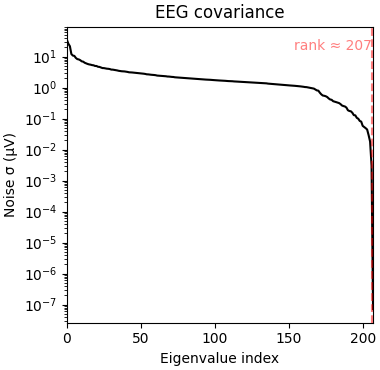

(<Figure size 380x370 with 2 Axes>, <Figure size 380x370 with 1 Axes>)

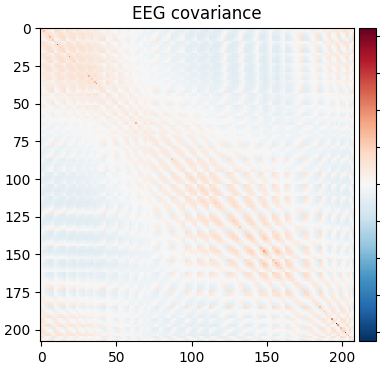

In [12]:
# ------------ Parameters -------------
tmax = 1.0
# -------------------------------------

noise_cov = mne.compute_covariance(data["eeg"], tmax=tmax, method="empirical")       # uses projectors (avg ref) of epochs
noise_cov.plot(data["eeg"].info)

📊 **Processed epochs**

Computing rank from covariance with rank=None
    Using tolerance 5.4e-13 (2.2e-16 eps * 208 dim * 12  max singular value)
    Estimated rank (eeg): 207
    EEG: rank 207 computed from 208 data channels with 1 projector


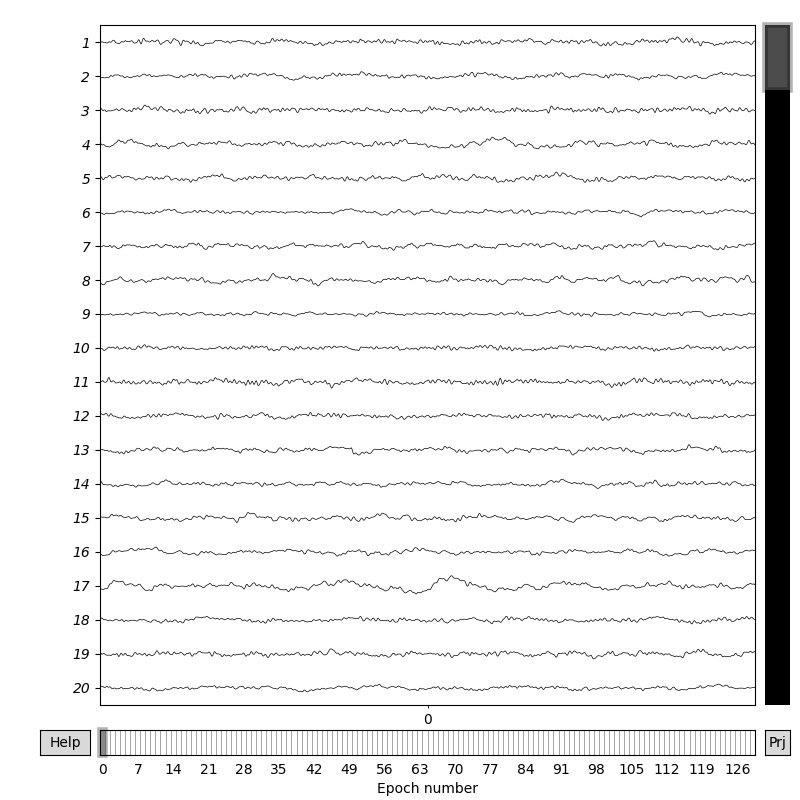

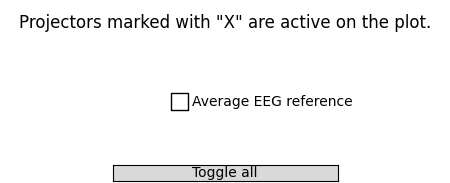

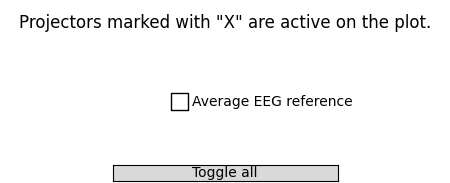

In [14]:
_ = data["eeg"].plot(
    n_epochs  = 1,          # number of epochs per view
    noise_cov = noise_cov,  # for whitening
)

#### 7. Average epochs

In [15]:
evoked = data["eeg"].average()

📊 **Averaged EEG signal**

🎚️ **<font color=pink>Plot options</font>**:
- `tmin`: minimum time point
- `tmax`: maximum time point

Created an SSP operator (subspace dimension = 1)
1 projection items activated
SSP projectors applied...


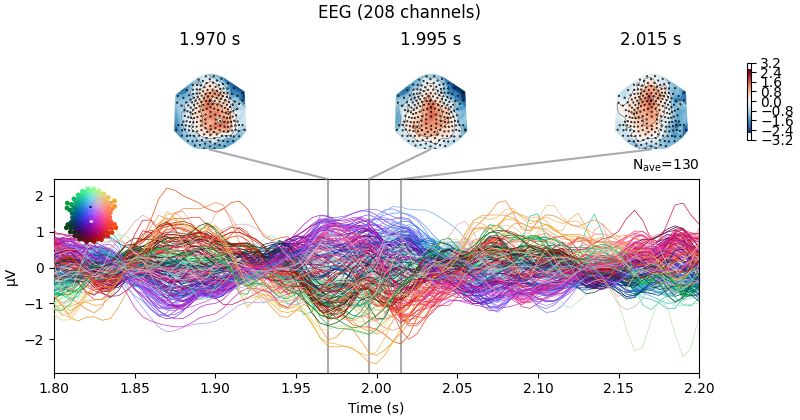

In [16]:
# ------------ Parameters -------------
tmin = 1.8
tmax = 2.2
# -------------------------------------

evoked_plot = evoked.copy()
_ = evoked_plot.crop(tmin=tmin, tmax=tmax).plot_joint(topomap_args={"extrapolate":"local"})

## 💾 Save processed EEG and noise covariance

🎚️ **<font color=pink>Save options</font>**:
- `overwrite`: Overwrites if file already exists.

In [ ]:
# ------------ parameters -----------
overwrite = True
# -----------------------------------

# file names
feeg = mm.io.get_bidspath(
    root     = reader.config["MM_DIR"],
    subject  = data["sub"],
    datatype = "ave",
    session  = None,
    task     = data["task"],
    run      = data["run"],
)

fcov = mm.io.get_bidspath(
    root     = reader.config["MM_DIR"],
    subject  = data["sub"],
    datatype = "cov",
    session  = None,
    task     = data["task"],
    run      = data["run"],
)

# save eeg
feeg.parent.mkdir(parents=True, exist_ok=True)
evoked.save(feeg, overwrite=overwrite)

print(f"\033[92mSuccessfully saved preprocessed EEG for subject '{data['sub']}', task '{data['task']}, run {data['run']}.\033[0m")

# save noise covariance
fcov.parent.mkdir(parents=True, exist_ok=True)
noise_cov.save(fcov, overwrite=True)

print(f"\033[92mSuccessfully saved noise covariance for subject '{data['sub']}', task '{data['task']}, run {data['run']}.")


Successfully saved preprocessed EEG for subject '10', task 'rest, run 11.
Successfully saved noise covariance for subject '10', task 'rest, run 11.
